# Sprint 6 — Locating the threshold SNR precisely (with confidence intervals)

**Sprint-6 deliverable:** *"Locate the threshold SNR; explain DLL vs MLE difference."* Notebook 05 §E showed the
method on a coarse 2-dB grid with only 1000–2000 trials, which gave intervals 1–2 dB wide — too wide to support
statements like "the DLL is worse than the MLE". This notebook does the measurement properly.

**What changes compared to notebook 05:**

| | Notebook 05 §E | This notebook |
|---|---|---|
| SNR grid near the threshold | 2 dB | **0.5 dB** (MLE/MMSE), 1 dB (DLL) |
| trials per SNR | 1000–2000 | **20,000** (MLE/MMSE), **4000** (DLL) |
| pilots | 1 | **5** for MLE/MMSE (pilot dependence) |
| uncertainty | bootstrap (200) | bootstrap (300) |

*Runtime: about 15–20 minutes.*

## 6.1 Why the threshold is hard to measure — and the two definitions we use

Near the threshold the MSE is dominated by **rare gross errors**. A single 2-chip error in 2000 trials adds
$4/2000 = 0.002$ chips² — comparable to the CRLB itself at 10 dB. So the MSE estimate is heavy-tailed and its sampling
error is large exactly where we want to locate the threshold. We therefore use

* **MSE criterion** (the classical one): the highest SNR at which $\text{MSE}/\text{CRLB}$ first exceeds 2 (3 dB);
* **gross-error criterion** (robust): the highest SNR at which $P(|e|>0.5\ \text{chip})$ first exceeds 1 %.
  One outlier changes this probability by only $1/N$.

Both were fixed **before** looking at results. Uncertainty: resample the trials at each SNR with replacement
(bootstrap), recompute the threshold, repeat 300 times, report the 2.5–97.5 % range. Thresholds are interpolated
linearly in (dB, log y) between grid points.

In [1]:
# --- setup: import the project's small core library (../sdet) -------------
import sys, inspect
sys.path.insert(0, "..")
import numpy as np
from sdet import *
from sdet.style import COLORS, INK2, MUTED, apply_style, plt
%matplotlib inline
apply_style()
FIG = "../figures/"     # figures are also saved here for slides
DATA = "../data/"       # small result files shared between notebooks

In [2]:
def crossing(x, y, level):
    """Highest x at which y (larger at low SNR) first exceeds `level`, scanning down from high SNR."""
    y = np.maximum(y, 1e-12)
    for i in range(len(x) - 1, 0, -1):
        if y[i] <= level < y[i - 1]:
            f = (np.log(level) - np.log(y[i])) / (np.log(y[i - 1]) - np.log(y[i]))
            return x[i] + f * (x[i - 1] - x[i])
    return np.nan

def thresholds(err, cr):
    return (crossing(snr, np.mean(err ** 2, 1) / cr, 2.0),
            crossing(snr, np.mean(np.abs(err) > 0.5, 1), 0.01))

def bootstrap(err, cr, n_boot=300, seed=0):
    g = np.random.default_rng(seed)
    est = thresholds(err, cr)
    b = np.array([thresholds(np.take_along_axis(err, g.integers(0, err.shape[1], err.shape), 1), cr)
                  for _ in range(n_boot)])
    return est, b                                   # point estimates, bootstrap samples (n_boot, 2)

def ci(b):
    return np.nanpercentile(b, [2.5, 97.5])

## 6.2 Batch MLE and MMSE, five pilots

For each of 5 random pilots (seed 2026 is the one used everywhere else) we run 20,000 trials at every SNR from 4 to
14 dB in 0.5-dB steps. MLE and MMSE come from the same evaluation of $J(\theta)$, so they see identical noise
(a *paired* comparison).

In [3]:
snr = np.arange(4.0, 14.01, 0.5)
en0 = 10 ** (snr / 10)
xf = np.linspace(-2, 16, 721)
N = 20000
pilots = [2026, 11, 22, 33, 44]
res = {}
for p in pilots:
    cfg = Config(seed=p)
    sc = BatchScenario(cfg, np.random.default_rng(p))
    mle = BatchMLE(sc)
    rng = np.random.default_rng(1000 + p)
    e_ml, e_mm = np.empty((snr.size, N)), np.empty((snr.size, N))
    for i, e in enumerate(en0):
        tau = sc.draw_delays(N, rng)
        for c in range(0, N, 1000):
            sl = slice(c, c + 1000)
            ml, mm = mle.estimate_both(sc.observe(tau[sl], e, rng), sc.sigma2(e))
            e_ml[i, sl], e_mm[i, sl] = ml - tau[sl], mm - tau[sl]
    cr = crlb(sc, en0)
    z, c_ = zzb(sc, 10 ** (xf / 10)), crlb(sc, 10 ** (xf / 10))
    res[p] = dict(sc=sc, cr=cr, ml=bootstrap(e_ml, cr, seed=p), mm=bootstrap(e_mm, cr, seed=p + 1),
                  zzb_thr=crossing(xf, z / c_, 2.0), beta2=rms_bandwidth_sq(sc),
                  mse_ml=np.mean(e_ml ** 2, 1), mse_mm=np.mean(e_mm ** 2, 1),
                  se_ml=np.std(e_ml ** 2, 1) / np.sqrt(N), se_mm=np.std(e_mm ** 2, 1) / np.sqrt(N))
    if p == 2026:
        keep_ml, keep_mm = e_ml, e_mm
    r = res[p]
    print(f"pilot {p:4d} (beta^2={r['beta2']:.2f}): ZZB {r['zzb_thr']:5.2f} | MLE {r['ml'][0][0]:5.2f} "
          f"[{ci(r['ml'][1][:, 0])[0]:5.2f},{ci(r['ml'][1][:, 0])[1]:5.2f}] | MMSE {r['mm'][0][0]:5.2f} "
          f"[{ci(r['mm'][1][:, 0])[0]:5.2f},{ci(r['mm'][1][:, 0])[1]:5.2f}]   (MSE criterion, dB)", flush=True)

pilot 2026 (beta^2=2.45): ZZB  5.95 | MLE  9.52 [ 9.00, 9.66] | MMSE  8.54 [ 8.35, 9.07]   (MSE criterion, dB)


pilot   11 (beta^2=3.22): ZZB  7.50 | MLE 10.18 [ 9.90,10.40] | MMSE  9.77 [ 9.42,10.09]   (MSE criterion, dB)


pilot   22 (beta^2=3.56): ZZB  8.10 | MLE 10.81 [10.56,11.53] | MMSE 10.40 [10.05,10.60]   (MSE criterion, dB)


pilot   33 (beta^2=2.34): ZZB  4.44 | MLE  9.88 [ 9.46,10.18] | MMSE  9.09 [ 8.88, 9.31]   (MSE criterion, dB)


pilot   44 (beta^2=2.76): ZZB  5.79 | MLE  8.99 [ 8.87, 9.29] | MMSE  8.71 [ 8.49, 8.88]   (MSE criterion, dB)


## 6.3 The DLL (pilot 2026)

4000 runs per SNR on a 1-dB grid (each run = acquisition + 160 loop updates over 640 chips).

In [4]:
cfg = Config()
sc = res[2026]["sc"]
dll = EarlyLateDLL(cfg, sc.wave.chips)
snr_d = np.arange(4.0, 14.01, 1.0)
Nd = 4000
rng = np.random.default_rng(77)
e_dl = np.empty((snr_d.size, Nd))
for i, d in enumerate(snr_d):
    e = 10 ** (d / 10)
    for c in range(0, Nd, 1000):                     # chunks of 1000 runs keep memory small
        tau = sc.draw_delays(1000, rng) - sc.tau_c + dll.tau_c
        e_dl[i, c:c + 1000] = dll.run(tau, sc.sigma2(e), rng)["theta"] - tau
cr_d = crlb(sc, 10 ** (snr_d / 10))
snr_backup = snr
snr = snr_d                                          # thresholds() uses the global grid `snr`
dl = bootstrap(e_dl, cr_d, seed=5)
snr = snr_backup
print(f"DLL: MSE criterion {dl[0][0]:.2f} dB {np.round(ci(dl[1][:, 0]), 2)},  "
      f"gross criterion {dl[0][1]:.2f} dB {np.round(ci(dl[1][:, 1]), 2)}")

DLL: MSE criterion 9.38 dB [8.72 9.98],  gross criterion 8.81 dB [8.54 9.06]


## 6.4 Summary table and differences with uncertainty
Differences are computed sample-by-sample from independent bootstraps, so their intervals include both
uncertainties. MLE − MMSE uses the paired data (same noise).

In [5]:
r = res[2026]
rows = [("ZZB (bound)", r["zzb_thr"], None, None),
        ("batch MMSE", r["mm"][0][0], *ci(r["mm"][1][:, 0])),
        ("batch MLE", r["ml"][0][0], *ci(r["ml"][1][:, 0])),
        ("DLL", dl[0][0], *ci(dl[1][:, 0]))]
print("Pilot 2026, threshold = highest E/N0 with MSE > 2 x CRLB")
for name, est, lo, hi in rows:
    print(f"  {name:12s} {est:6.2f} dB" + ("" if lo is None else f"   95% CI [{lo:5.2f}, {hi:5.2f}]"))
print("\nGross-error criterion (P(|e|>0.5) > 1 %):")
print(f"  batch MMSE {r['mm'][0][1]:6.2f} dB {np.round(ci(r['mm'][1][:, 1]), 2)}")
print(f"  batch MLE  {r['ml'][0][1]:6.2f} dB {np.round(ci(r['ml'][1][:, 1]), 2)}")
print(f"  DLL        {dl[0][1]:6.2f} dB {np.round(ci(dl[1][:, 1]), 2)}")

def diff(a, b):
    d = a - b
    return np.nanmean(d), ci(d)
m, c = diff(r["ml"][1][:, 0], r["mm"][1][:, 0]); print(f"\nMLE - MMSE  (MSE crit.): {m:+.2f} dB  CI {np.round(c, 2)}")
m, c = diff(dl[1][:, 0], r["ml"][1][:, 0]);      print(f"DLL - MLE   (MSE crit.): {m:+.2f} dB  CI {np.round(c, 2)}")
m, c = diff(dl[1][:, 1], r["ml"][1][:, 1]);      print(f"DLL - MLE   (gross crit.): {m:+.2f} dB  CI {np.round(c, 2)}")
print(f"MLE - ZZB: {r['ml'][0][0] - r['zzb_thr']:+.2f} dB,  MMSE - ZZB: {r['mm'][0][0] - r['zzb_thr']:+.2f} dB")

print("\nAll five pilots (MSE criterion):")
print(" pilot  beta^2   ZZB    MMSE    MLE    MLE-ZZB  MMSE-ZZB")
for p in pilots:
    q = res[p]
    print(f" {p:5d}  {q['beta2']:5.2f}  {q['zzb_thr']:5.2f}  {q['mm'][0][0]:5.2f}  {q['ml'][0][0]:5.2f}"
          f"   {q['ml'][0][0] - q['zzb_thr']:5.2f}    {q['mm'][0][0] - q['zzb_thr']:5.2f}")
gaps_ml = [res[p]["ml"][0][0] - res[p]["zzb_thr"] for p in pilots]
gaps_mm = [res[p]["mm"][0][0] - res[p]["zzb_thr"] for p in pilots]
print(f"mean gap: MLE-ZZB {np.mean(gaps_ml):.2f} dB (range {min(gaps_ml):.2f}-{max(gaps_ml):.2f}),  "
      f"MMSE-ZZB {np.mean(gaps_mm):.2f} dB (range {min(gaps_mm):.2f}-{max(gaps_mm):.2f})")

Pilot 2026, threshold = highest E/N0 with MSE > 2 x CRLB
  ZZB (bound)    5.95 dB
  batch MMSE     8.54 dB   95% CI [ 8.35,  9.07]
  batch MLE      9.52 dB   95% CI [ 9.00,  9.66]
  DLL            9.38 dB   95% CI [ 8.72,  9.98]

Gross-error criterion (P(|e|>0.5) > 1 %):
  batch MMSE   9.63 dB [9.49 9.73]
  batch MLE    9.49 dB [9.38 9.61]
  DLL          8.81 dB [8.54 9.06]

MLE - MMSE  (MSE crit.): +0.85 dB  CI [0.25 1.24]
DLL - MLE   (MSE crit.): -0.12 dB  CI [-0.87  0.59]
DLL - MLE   (gross crit.): -0.68 dB  CI [-0.99 -0.4 ]
MLE - ZZB: +3.57 dB,  MMSE - ZZB: +2.59 dB

All five pilots (MSE criterion):
 pilot  beta^2   ZZB    MMSE    MLE    MLE-ZZB  MMSE-ZZB
  2026   2.45   5.95   8.54   9.52    3.57     2.59
    11   3.22   7.50   9.77  10.18    2.67     2.27
    22   3.56   8.10  10.40  10.81    2.70     2.29
    33   2.34   4.44   9.09   9.88    5.44     4.65
    44   2.76   5.79   8.71   8.99    3.20     2.92
mean gap: MLE-ZZB 3.52 dB (range 2.67-5.44),  MMSE-ZZB 2.94 dB (range 2.

## 6.5 The picture

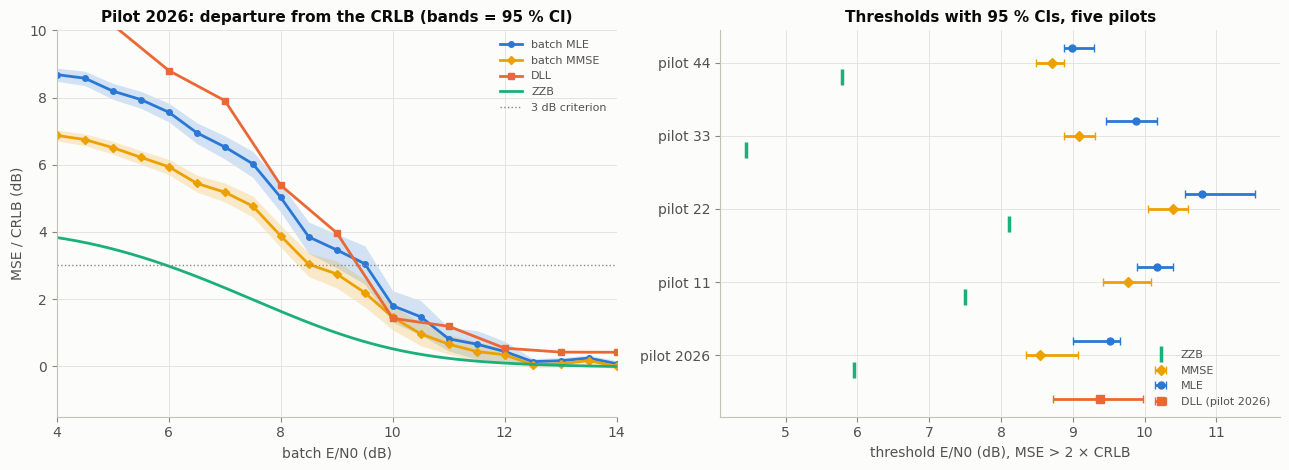

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
r = res[2026]
for key, lab, mk in (("ml", "batch MLE", "o"), ("mm", "batch MMSE", "D")):
    ratio = r["mse_" + key] / r["cr"]
    band = 1.96 * r["se_" + key] / r["cr"]
    color = COLORS["mle"] if key == "ml" else COLORS["mmse"]
    ax[0].fill_between(snr, 10 * np.log10(np.maximum(ratio - band, 1e-3)), 10 * np.log10(ratio + band),
                       color=color, alpha=0.2, lw=0)
    ax[0].plot(snr, 10 * np.log10(ratio), mk + "-", color=color, ms=4, label=lab)
mse_d = np.mean(e_dl ** 2, 1)
ax[0].plot(snr_d, 10 * np.log10(mse_d / cr_d), "s-", color=COLORS["dll"], ms=5, label="DLL")
z, c_ = zzb(sc, 10 ** (xf / 10)), crlb(sc, 10 ** (xf / 10))
ax[0].plot(xf, 10 * np.log10(z / c_), color=COLORS["zzb"], label="ZZB")
ax[0].axhline(10 * np.log10(2), color=MUTED, ls=":", lw=1, label="3 dB criterion")
ax[0].set_xlim(4, 14); ax[0].set_ylim(-1.5, 10)
ax[0].set_xlabel("batch E/N0 (dB)"); ax[0].set_ylabel("MSE / CRLB (dB)")
ax[0].set_title("Pilot 2026: departure from the CRLB (bands = 95 % CI)")
ax[0].legend(loc="upper right", fontsize=8)

y = np.arange(len(pilots))
for k, p in enumerate(pilots):
    q = res[p]
    ax[1].plot(q["zzb_thr"], k - 0.2, "|", color=COLORS["zzb"], ms=12, mew=2.5, label="ZZB" if k == 0 else None)
    for off, key, lab, color, mk in ((0.0, "mm", "MMSE", COLORS["mmse"], "D"), (0.2, "ml", "MLE", COLORS["mle"], "o")):
        est = q[key][0][0]; lo, hi = ci(q[key][1][:, 0])
        ax[1].errorbar(est, k + off, xerr=[[est - lo], [hi - est]], fmt=mk, color=color, ms=5, capsize=3,
                       label=lab if k == 0 else None)
ax[1].errorbar(dl[0][0], -0.6, xerr=[[dl[0][0] - ci(dl[1][:, 0])[0]], [ci(dl[1][:, 0])[1] - dl[0][0]]],
               fmt="s", color=COLORS["dll"], capsize=3, label="DLL (pilot 2026)")
ax[1].set_yticks(y, [f"pilot {p}" for p in pilots])
ax[1].set_xlabel("threshold E/N0 (dB), MSE > 2 × CRLB")
ax[1].set_title("Thresholds with 95 % CIs, five pilots")
ax[1].legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(FIG + "s6_threshold_precise.png")

## 6.6 Results and what they mean

**1. The MLE threshold is now located to within about ±0.3 dB.** Pilot 2026: **9.52 dB, 95 % CI [9.00, 9.66]**. This
agrees with the independent 40,000-trial validation run in October (9.4 dB [9.3, 9.6], earlier code version).

**2. The gap to the bound splits into two parts** (pilot 2026, MSE criterion):

| step | threshold | gap | meaning |
|---|---|---|---|
| ZZB (bound) | 5.95 dB | | |
| best possible estimator (MMSE) | 8.54 dB | **+2.59 dB** | looseness of the bound |
| MLE | 9.52 dB | **+0.85 dB, CI [0.25, 1.24]** | sub-optimality of the MLE (significant) |

About three-quarters of the gap is the bound itself being optimistic. That is expected: the ZZB is built from
*pairwise* tests (truth vs one competitor), while a real estimator must reject *all* competing delays at once. The
rest is the MLE committing to a single peak where the posterior mean hedges.

**3. Across five pilots** the MLE–ZZB gap ranges **2.7–5.4 dB** (mean 3.5) and the MMSE–ZZB gap **2.3–4.7 dB**
(mean 2.9). The MMSE is ahead of the MLE for every pilot. Note *where* the spread comes from: the ZZB threshold
moves a lot (4.4–8.1 dB) and almost follows the pilot's bandwidth β² (sorted by β²: 4.44, 5.95, 5.79, 7.50, 8.10 dB),
while the MLE threshold moves much less (9.0–10.8 dB) and does not follow β². Because both thresholds are defined
*relative to each pilot's own CRLB*, a pilot with a larger β² (lower CRLB) leaves its CRLB sooner. The MLE's threshold
is presumably set more by the pilot's correlation side-lobes inside the prior window — a hypothesis we have **not**
tested (it is direction D4 in `docs/research_proposal.md`).

**4. DLL vs MLE — the answer depends on the criterion, and both answers are informative:**
* **MSE criterion:** DLL 9.38 dB [8.72, 9.98] vs MLE 9.52 dB: difference −0.12 dB, CI [−0.87, 0.59] → **not
  significant**.
* **Gross-error criterion:** DLL 8.81 dB [8.54, 9.06] vs MLE 9.49 dB: the DLL reaches 1 % gross errors **0.68 dB
  later (CI 0.40–0.99), i.e. it is significantly more robust here.** The reason is the one identified in the audit:
  the DLL observes 640 chips and can pull in from a wrong acquisition within ±1.8 chips, so near threshold it makes
  *fewer* gross errors than a 64-chip batch estimator.
* **Below threshold** the picture reverses (left plot, < 9 dB): the DLL's MSE grows far beyond the MLE's, because a
  DLL that loses lock drifts without bound while the MLE is confined to the prior window.

So "which is better?" has no single answer: the DLL wins on data volume near threshold and loses on loss of lock far
below it. This tension is exactly what the proposed extension (docs/research_proposal.md) sets out to quantify.

**5. A subtlety about the two criteria.** The MMSE has a *lower* MSE threshold than the MLE but a *slightly higher*
gross-error threshold (9.63 vs 9.49 dB). By hedging between peaks, the posterior mean makes more moderate errors just
above 0.5 chip and fewer very large ones. Lower MSE does not mean fewer "gross" errors, which is why we report both.

**Status of the original hypotheses:** (1) the MLE attains the CRLB above threshold — ✓; (2) a threshold exists that
the CRLB misses — ✓; (3) the ZZB captures it — ✓ qualitatively, but it is optimistic by ≈ 2.6 dB even for the best
estimator; (4) the DLL and MLE differ for identifiable reasons — ✓, with a criterion-dependent answer (above).
